In [2]:
import pandas as pd

# GitHub dataset URL
url = "https://raw.githubusercontent.com/ybifoundation/Dataset/main/Ice%20Cream.csv"

# Load dataset
df = pd.read_csv(url)

# Display first 5 rows
print(df.head())

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("Columns:", df.columns.tolist())

   Temperature  Revenue
0         24.6      535
1         26.1      626
2         27.8      661
3         20.6      488
4         11.6      317
Dataset Shape: (500, 2)
Columns: ['Temperature', 'Revenue']


In [3]:
# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Display last 5 rows
print("Last 5 Rows:")
display(df.tail())

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

First 5 Rows:


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


Last 5 Rows:


,Temperature,Revenue
495,22.3,525
496,32.9,756
497,12.6,307
498,22.4,567
499,29.0,656


Dataset Shape: (500, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  500 non-null    float64
 1   Revenue      500 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 7.9 KB

Statistical Summary:


,Temperature,Revenue
count,500.000000,500.000000
mean,22.281600,522.058000
std,8.097597,175.410399
min,0.000000,10.000000
25%,17.175000,406.000000
50%,22.400000,530.000000
75%,27.800000,643.000000
max,45.000000,1000.000000



Missing Values:
Temperature    0
Revenue        0
dtype: int64


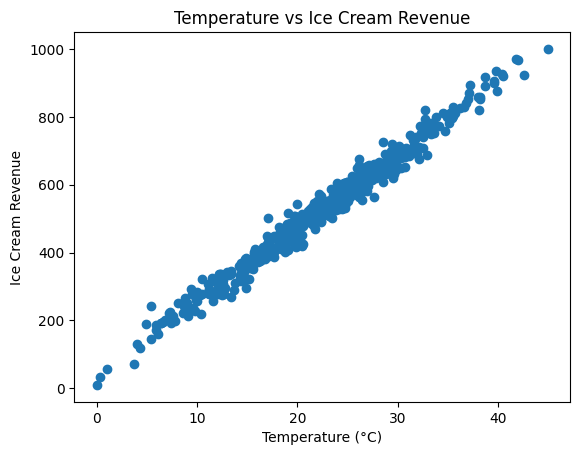

In [4]:
import matplotlib.pyplot as plt

# Create scatter plot
plt.scatter(df['Temperature'], df['Revenue'])

# Add title
plt.title('Temperature vs Ice Cream Revenue')

# Add X-axis label
plt.xlabel('Temperature (°C)')

# Add Y-axis label
plt.ylabel('Ice Cream Revenue')

# Display graph
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

# Independent variable
X = df[['Temperature']]

# Dependent variable
y = df['Revenue']

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display dataset sizes
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (400, 1)
Testing Data: (100, 1)
Training Target: (400,)
Testing Target: (100,)


In [6]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Display model parameters
print("Model Training Completed Successfully!")

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Model Training Completed Successfully!
Slope: 21.384000731002768
Intercept: 46.17834580774047


In [7]:
# Predict revenue using testing data
y_pred = model.predict(X_test)

# Display actual and predicted values
result = pd.DataFrame({
    'Actual Revenue': y_test.values,
    'Predicted Revenue': y_pred
})

print(result.head(10))

   Actual Revenue  Predicted Revenue
0             660         683.421568
1             624         632.099966
2             560         559.394363
3             498         499.519161
4             628         614.992765
5             301         304.924755
6             279         285.679154
7             320         315.616755
8             484         505.934362
9             684         685.559968


In [8]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("R2 Score (%):", r2 * 100)

Model Evaluation Results
------------------------
MAE: 19.195652579103704
MSE: 652.4938284912412
RMSE: 25.543958747446354
R2 Score: 0.9771509516333023
R2 Score (%): 97.71509516333023


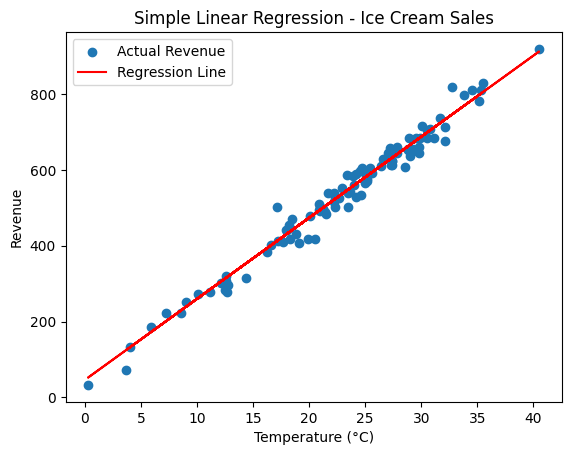

In [9]:
import matplotlib.pyplot as plt

# Plot actual data
plt.scatter(X_test, y_test, label='Actual Revenue')

# Plot regression line
plt.plot(X_test, y_pred, color='red', label='Regression Line')

# Add title and labels
plt.title('Simple Linear Regression - Ice Cream Sales')
plt.xlabel('Temperature (°C)')
plt.ylabel('Revenue')

# Display legend
plt.legend()

# Display graph
plt.show()

In [10]:
# Take temperature as input
temperature = 27

# Predict revenue
predicted_revenue = model.predict(
    pd.DataFrame({'Temperature': [temperature]})
)

# Display prediction
print("Temperature:", temperature, "°C")
print("Predicted Ice Cream Revenue:", predicted_revenue[0])

Temperature: 27 °C
Predicted Ice Cream Revenue: 623.5463655448152


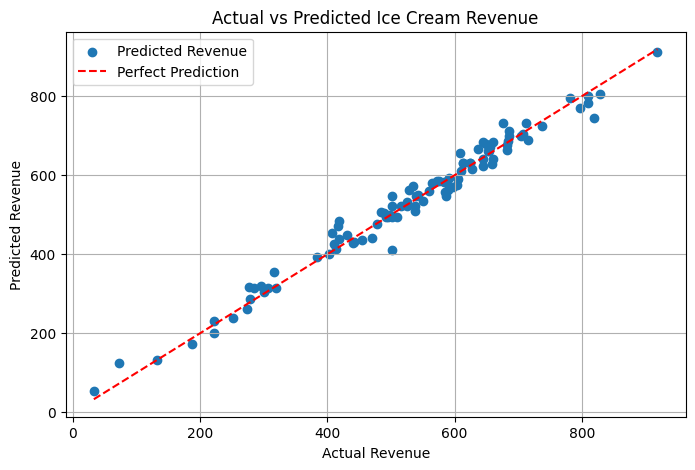

In [11]:
import matplotlib.pyplot as plt

# Create scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, label='Predicted Revenue')

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

# Add title and labels
plt.title('Actual vs Predicted Ice Cream Revenue')
plt.xlabel('Actual Revenue')
plt.ylabel('Predicted Revenue')

# Display legend
plt.legend()

# Display grid
plt.grid(True)

# Show graph
plt.show()